# Historeceptomics Quickstart

This self-contained demonstration uses **entirely invented data**: two fictional compounds, four fictional targets, and 32 fictional tissues. It teaches the computational method; it is not evidence about ketamine and does not reproduce the accepted reference results.

**HR score = target pharmacological activity × within-gene standardized tissue expression.** The HR-score matrix contains all calculated values. A fingerprint contains only upper-tail outliers selected with the project's actual one-sided GESD implementation. Primary α = 0.001; sensitivity α = 0.0001. Fingerprint comparison is the principal analytical approach; continuous HR comparison is exploratory.

Run from the repository root or `notebooks/`. Installation and command-line execution are documented in [the notebook guide](README.md). No network or restricted input is used during execution.

In [1]:
from pathlib import Path
import sys
import importlib.metadata as metadata

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "cardozo_ketamine_hr").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src" / "cardozo_ketamine_hr").is_dir(), "Run inside the repository root or notebooks/"
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from cardozo_ketamine_hr.expression import standardize_within_gene
from cardozo_ketamine_hr.hr import construct_hr_scores
from cardozo_ketamine_hr.fingerprint import gesd_upper
from cardozo_ketamine_hr.pairwise_fingerprint import build_call_matrices, one_alpha

print("Synthetic demonstration; no scientific input downloads")
print({name: metadata.version(name) for name in ("numpy", "pandas", "scipy", "matplotlib")})

Synthetic demonstration; no scientific input downloads
{'numpy': '2.5.1', 'pandas': '3.0.5', 'scipy': '1.18.0', 'matplotlib': '3.11.1'}


## 1. Load compound–target activity and tissue expression

The CSV values were invented for this notebook. Activity is already expressed as a target-level pActivity value, so assay curation and affinity conversion are outside this compact example. Relation `=` denotes an exact synthetic value. The missing activity for `SYNTHETIC_A` / `SYNTH_TARGET_4` is deliberate: unsupported coordinates must remain missing, never zero.

Expression values are arbitrary, positive numbers in invented units. Distinctive peaks make the outlier-selection step visible.

In [2]:
fixtures = ROOT / "notebooks" / "fixtures"
activity = pd.read_csv(fixtures / "activity.csv")
expression = pd.read_csv(fixtures / "expression.csv")
assert len(activity) == 8 and len(expression) == 128
assert activity.duplicated(["profile_id", "canonical_target_id"]).sum() == 0
assert expression.duplicated(["canonical_target_id", "tissue_id"]).sum() == 0
display(activity)
display(expression.head())

,profile_id,canonical_target_id,final_selected_pActivity_v4,final_activity_relation_operator_v4
0,SYNTHETIC_A,SYNTH_TARGET_1,6.0,=
1,SYNTHETIC_A,SYNTH_TARGET_2,4.0,=
2,SYNTHETIC_A,SYNTH_TARGET_3,1.0,=
3,SYNTHETIC_A,SYNTH_TARGET_4,NaN,=
4,SYNTHETIC_B,SYNTH_TARGET_1,6.0,=
5,SYNTHETIC_B,SYNTH_TARGET_2,0.2,=
6,SYNTHETIC_B,SYNTH_TARGET_3,1.0,=
7,SYNTHETIC_B,SYNTH_TARGET_4,7.0,=


,canonical_target_id,gene_symbol,tissue_id,raw_expression
0,SYNTH_TARGET_1,SYNTH_GENE_1,SYNTH_TISSUE_01,10.05
1,SYNTH_TARGET_1,SYNTH_GENE_1,SYNTH_TISSUE_02,10.10
2,SYNTH_TARGET_1,SYNTH_GENE_1,SYNTH_TISSUE_03,10.15
3,SYNTH_TARGET_1,SYNTH_GENE_1,SYNTH_TISSUE_04,10.20
4,SYNTH_TARGET_1,SYNTH_GENE_1,SYNTH_TISSUE_05,10.25


## 2. Standardize expression within each gene

The scientific implementation uses the sample standard deviation (`ddof=1`). All 32 tissues define each synthetic gene's standardization universe. A zero-variance or insufficiently observed gene would remain unsupported rather than receiving a fabricated z-score.

In [3]:
standardized = standardize_within_gene(expression, ddof=1)
checks = standardized.groupby("gene_symbol")["expression_z"].agg(["mean", "std"])
np.testing.assert_allclose(checks["mean"], 0.0, atol=1e-12)
np.testing.assert_allclose(checks["std"], 1.0, atol=1e-12)
display(checks)

,mean,std
gene_symbol,,
SYNTH_GENE_1,5.551115e-17,1.0
SYNTH_GENE_2,-2.428613e-17,1.0
SYNTH_GENE_3,1.533496e-15,1.0
SYNTH_GENE_4,-5.724587e-17,1.0


## 3. Calculate HR scores and construct a matrix

`construct_hr_scores` joins exact target identifiers and calculates the product. For each profile the matrix rows are targets and columns are tissues. The long table retains source values and the exact synthetic relation operator. A negative standardized expression can produce a negative HR score; it is not evidence of an inhibitory mechanism.

In [4]:
profiles = activity["profile_id"].drop_duplicates().tolist()
hr_tables = {}
for profile in profiles:
    hr_tables[profile] = construct_hr_scores(
        activity.loc[activity["profile_id"].eq(profile)], standardized
    )

matrix_a = hr_tables["SYNTHETIC_A"].pivot(
    index="canonical_target_id", columns="tissue_id", values="hr_score"
)
assert matrix_a.shape == (4, 32)
assert matrix_a.loc["SYNTH_TARGET_4"].isna().all()
display(matrix_a.iloc[:, :6])
print("A: supported coordinates =", int(matrix_a.notna().sum().sum()),
      "; unsupported coordinates =", int(matrix_a.isna().sum().sum()))

tissue_id,SYNTH_TISSUE_01,SYNTH_TISSUE_02,SYNTH_TISSUE_03,SYNTH_TISSUE_04,SYNTH_TISSUE_05,SYNTH_TISSUE_06
canonical_target_id,,,,,,
SYNTH_TARGET_1,-1.243327,-1.231138,-1.218948,-1.206759,-1.194569,-1.182380
SYNTH_TARGET_2,-0.829147,-0.821020,-0.812894,-0.804768,-0.796641,-0.788515
SYNTH_TARGET_3,-1.652306,-1.545705,-1.439105,-1.332504,-1.225904,-1.119304
SYNTH_TARGET_4,NaN,NaN,NaN,NaN,NaN,NaN


A: supported coordinates = 96 ; unsupported coordinates = 32


## 4. Select fingerprints with the actual GESD implementation

The test is one-sided and upper-tail. Only finite HR values enter testing; the default candidate limit is `floor(0.10 × n_finite)`. The ordered removals through the final significant GESD step form the fingerprint. The code below directly calls the repository implementation, without an approximate reimplementation or a fixed call-count target.

Primary and sensitivity thresholds are tested separately on each profile's full supported candidate set. A fingerprint table alone does not tell us whether every omitted coordinate was tested.

In [5]:
thresholds = {"primary": 0.001, "sensitivity": 0.0001}
call_tables = {name: [] for name in thresholds}
summary = []
for profile, hr in hr_tables.items():
    for name, alpha in thresholds.items():
        indices, steps = gesd_upper(hr["hr_score"].to_numpy(float), alpha=alpha)
        calls = hr.iloc[indices].copy()
        calls["drug"] = profile
        calls["feature_id_common"] = calls["feature_id"]
        calls["raw_hr"] = calls["hr_score"]
        call_tables[name].append(calls)
        summary.append({"profile": profile, "threshold": name, "alpha": alpha,
                        "tested": int(hr["hr_score"].notna().sum()), "calls": len(calls)})
        if profile == "SYNTHETIC_A" and name == "primary":
            display(steps.head(4))

calls_by_threshold = {name: pd.concat(frames, ignore_index=True)
                      for name, frames in call_tables.items()}
display(pd.DataFrame(summary))
display(calls_by_threshold["primary"][["drug", "canonical_target_id", "tissue_id", "raw_hr"]])

,step,n,removed_index,removed_value,GESD_R,critical_lambda,R_minus_lambda
0,1,96,31,32.875037,7.905135,4.068630,3.836504
1,2,95,62,21.916646,9.196507,4.064661,5.131846
2,3,94,95,1.652306,3.049771,4.060634,-1.010863
3,4,93,94,1.545705,3.081163,4.056549,-0.975386


,profile,threshold,alpha,tested,calls
0,SYNTHETIC_A,primary,0.0010,96,2
1,SYNTHETIC_A,sensitivity,0.0001,96,2
2,SYNTHETIC_B,primary,0.0010,128,2
3,SYNTHETIC_B,sensitivity,0.0001,128,2


,drug,canonical_target_id,tissue_id,raw_hr
0,SYNTHETIC_A,SYNTH_TARGET_1,SYNTH_TISSUE_32,32.875037
1,SYNTHETIC_A,SYNTH_TARGET_2,SYNTH_TISSUE_31,21.916646
2,SYNTHETIC_B,SYNTH_TARGET_4,SYNTH_TISSUE_29,38.353987
3,SYNTHETIC_B,SYNTH_TARGET_1,SYNTH_TISSUE_32,32.875037


## 5. Keep calls, tested non-calls, and unsupported coordinates distinct

The package's call-matrix constructor encodes **1 = called**, **0 = tested non-call**, and **missing = unsupported or untested**. The HR-score matrix is a different object. We build feature metadata from the synthetic coordinates and preserve exact profile/target/tissue identities.

In [6]:
feature_contract = hr_tables[profiles[0]][["feature_id", "canonical_target_id", "tissue_id"]].rename(
    columns={"canonical_target_id": "target", "tissue_id": "tissue"}
)
feature_contract["feature_order"] = np.arange(len(feature_contract))
raw = pd.DataFrame({profile: hr.set_index("feature_id")["hr_score"]
                    for profile, hr in hr_tables.items()}).T
matrices = build_call_matrices(
    raw, calls_by_threshold["primary"], calls_by_threshold["sensitivity"],
    feature_contract, profiles
)
binary = matrices["call_binary_alpha001"]
assert binary.loc["SYNTHETIC_A", binary.columns.str.startswith("SYNTH_TARGET_4||")].isna().all()
assert set(binary.stack().dropna().unique()) <= {0.0, 1.0}
display(pd.DataFrame({"called": binary.eq(1).sum(axis=1),
                      "tested_noncall": binary.eq(0).sum(axis=1),
                      "unsupported": binary.isna().sum(axis=1)}))

,called,tested_noncall,unsupported
SYNTHETIC_A,2,94,32
SYNTHETIC_B,2,126,0


## 6. Compare two fingerprints

`one_alpha` computes the project's pairwise fingerprint metrics. Ordinary call Jaccard divides the shared calls by the call-set union. The jointly-tested version first restricts to coordinates supported for both profiles. These can differ when support differs. The overlap coefficient uses the smaller call set as denominator. None of these metrics establishes a clinical effect or causality.

In [7]:
comparison = one_alpha(
    profiles[0], profiles[1], binary, matrices["call_score_alpha001"], feature_contract
)
display(pd.Series({key: comparison[key] for key in (
    "call_count_a", "call_count_b", "shared_calls", "union_calls", "call_jaccard",
    "call_overlap_coefficient", "jointly_tested_call_jaccard", "signed_sparse_cosine"
)}, name="SYNTHETIC_A vs SYNTHETIC_B"))
print("Shared features:", comparison["shared_feature_ids"])

call_count_a                   2.000000
call_count_b                   2.000000
shared_calls                   1.000000
union_calls                    3.000000
call_jaccard                   0.333333
call_overlap_coefficient       0.500000
jointly_tested_call_jaccard    0.500000
signed_sparse_cosine           0.541493
Name: SYNTHETIC_A vs SYNTHETIC_B, dtype: float64

Shared features: SYNTH_TARGET_1||SYNTH_TISSUE_32


## 7. Visualize the synthetic HR-score matrix and fingerprint

Color represents the complete calculated HR scores for `SYNTHETIC_A`. White cells remain unsupported. Open circles mark primary GESD calls; the color scale is not a binary fingerprint scale. This illustration uses the already calculated synthetic values and never reads the frozen ketamine authorities.

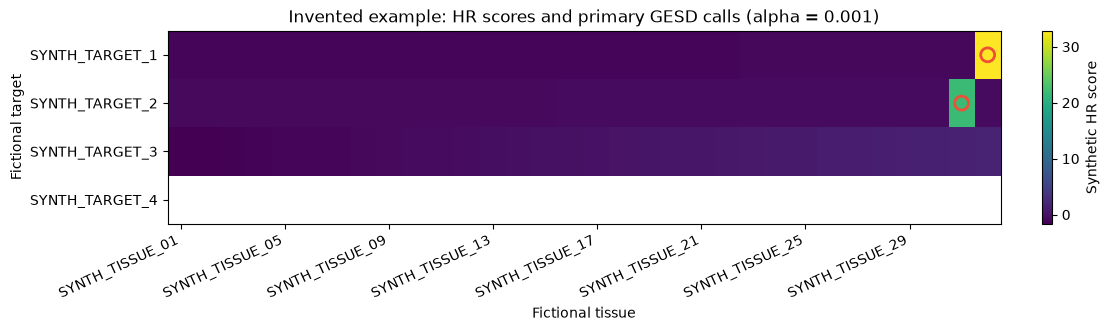

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.2), layout="constrained")
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("white")
image = ax.imshow(matrix_a.to_numpy(float), aspect="auto", cmap=cmap)
ax.set_yticks(range(len(matrix_a.index)), matrix_a.index)
ax.set_xticks(range(0, 32, 4), matrix_a.columns[::4], rotation=25, ha="right")
for row in calls_by_threshold["primary"].query("drug == 'SYNTHETIC_A'").itertuples():
    ax.scatter(matrix_a.columns.get_loc(row.tissue_id),
               matrix_a.index.get_loc(row.canonical_target_id),
               s=100, facecolors="none", edgecolors="#f04e37", linewidths=2)
ax.set(title="Invented example: HR scores and primary GESD calls (alpha = 0.001)",
       xlabel="Fictional tissue", ylabel="Fictional target")
fig.colorbar(image, ax=ax, label="Synthetic HR score")
plt.show()

## What to do next

For the complete scientific workflow, follow [the reproducibility guide](../docs/REPRODUCIBILITY.md). The public Smoke lane uses invented fixtures; Verify and Full require the separately obtained, manifest-validated inputs documented there. Do not treat this notebook's synthetic output as a substitute for accepted scientific results.

For downstream file exchange, see [application integration](../docs/APPLICATION_INTEGRATION.md). Exported datasets must preserve profile identity, threshold, provenance, and the distinction between tested non-calls and missing support.

Original notebook code and prose: MIT. The invented CSV fixtures and embedded synthetic data outputs: CC BY-SA 4.0 under [DATA_LICENSE.md](../DATA_LICENSE.md). No third-party measurements are included.